# Предобработка данных и регрессия на датасете «House Prices»

**Дисциплина:** Машинное обучение и искусственный интеллект  
**Модуль 2:** Предобработка данных и базовые алгоритмы регрессии  
**Датасет:** House Prices — Advanced Regression Techniques  
**Учебный год:** 2026/2027  

**Выполнил:** Брацун Данила  
**Группа:** ПКТб-23-1  
**Преподаватель:** Дисциплина «Машинное обучение и ИИ»  

**Ссылка на репозиторий:** [https://github.com/BratsunDanila/ml-course-bratsun](https://github.com/BratsunDanila/ml-course-bratsun)  
**Путь к модулю в репозитории:** `module-2-house-prices/notebook.ipynb`  
**Дата сдачи:** 2026-10-05  


## Введение

### 🎯 1. Постановка задачи
В данной работе решается задача **множественной регрессии**: прогнозирование рыночной стоимости жилой недвижимости ($SalePrice \in \mathbb{R}^+$) в городе Эймс (Айова, США) на основе 79 разнородных характеристик объекта (физические габариты, качество материалов отделки, возраст постройки, район расположения, инженерные коммуникации и особенности прилегающего участка).

### 🔄 2. Жизненный цикл ML-проекта регрессии
Разработка решения для задачи регрессии включает следующие обязательные этапы:
1. **Постановка проблемы и сбор данных:** формализация задачи, анализ природы целевой переменной.
2. **Разведочный анализ (EDA):** анализ асимметрии целевой переменной, исследование корреляций, выявление мультиколлинеарности и экстремальных выбросов.
3. **Трансформация целевой переменной:** применение логарифмического преобразования $y = \log(1 + SalePrice)$ для стабилизации дисперсии (гомоскедастичности) и приведения распределения к нормальному виду.
4. **Очистка данных:** дифференцированная обработка пропусков (разделение на смысловые «None»/0 и случайные пропуски) и удаление аномалий.
5. **Конструирование признаков (Feature Engineering):** создание агрегированных предикторов (`TotalSF`, `TotalBath`, `HouseAge`, `TotalPorchSF`).
6. **Кодирование категорий:** порядковое ранжирование качественных шкал (0–5) и One-Hot кодирование номинальных категорий.
7. **Масштабирование:** стандартизация признаков (`StandardScaler`), критически важная для регуляризованных моделей.
8. **Обучение моделей:** обучение семейства моделей с $L_1$- и $L_2$-регуляризацией (`LinearRegression`, `Ridge`, `Lasso`, `ElasticNet`).
9. **Кросс-валидация и оптимизация:** подбор силы регуляризации $\alpha$ с помощью 5-Fold `GridSearchCV`.
10. **Оценка качества и анализ остатков:** расчет метрик $R^2$, $RMSE$, $MAE$, построение графиков рассеяния и распределения ошибок.
11. **Интерпретация результатов:** анализ величины весов, выявление зануленных признаков в Lasso и содержательные выводы.
12. **Сериализация и инференс:** сохранение моделей, скейлера и словарей в `.pkl` и настройка удаленного инференса из GitHub.

### ❓ 3. Почему регрессия, а не классификация
В задачах классификации целевая переменная принадлежит конечному дискретному множеству классов (например, выжил/погиб в Титанике). В задаче House Prices целевая переменная $SalePrice$ является **непрерывной количественной величиной**, измеряемой в денежном эквиваленте на непрерывной шкале. Задача состоит в минимизации меры расхождения между истинной и спрогнозированной ценой на основе гладких функций потерь.

### 📊 4. Выбор метрик оценки качества
- **$R^2$ (Коэффициент детерминации):** доля дисперсии зависимой переменной, объясняемая моделью. Для хорошей модели $R^2 > 0.85 - 0.90$.
- **$RMSE$ (Root Mean Squared Error):** корень из среднеквадратичной ошибки. В логарифмической шкале соответствует метрике соревнования Kaggle (RMSLE), строго штрафует за единичные крупные промахи.
- **$MAE$ (Mean Absolute Error):** средняя абсолютная ошибка, выраженная в реальных долларах, что обеспечивает прозрачную бизнес-интерпретацию точности оценки.

### 🎯 5. Цели работы
1. Провести полный EDA, устранить сильную правостороннюю асимметрию целевой переменной ($Skewness = 1.88 \to 0.12$) и исключить доказанные экстремальные выбросы.
2. Сконструировать информативные агрегированные признаки и обучить модели линейной регрессии с $L_1$- и $L_2$-регуляризацией (`Ridge`, `Lasso`, `ElasticNet`), обеспечив на кросс-валидации и тесте качество $R^2 \ge 0.90$.
3. Реализовать готовую функцию оценки стоимости жилья `predict_price()`, сохранить артефакты в папку `models/` и протестировать удалённый инференс по ссылке из репозитория.


## Теоретическая часть

В рамках задачи регрессии исследуются фундаментальные эконометрические и математические концепции:

### 1. Метод наименьших квадратов (OLS — Ordinary Least Squares)
Классическая линейная регрессия находит вектор весов $\mathbf{w}$, минимизирующий сумму квадратов остатков:
$$\mathcal{L}_{OLS}(\mathbf{w}) = \frac{1}{n} \sum_{i=1}^n \left(y_i - \mathbf{w}^T \mathbf{x}_i\right)^2 = \frac{1}{n} \|\mathbf{y} - \mathbf{X}\mathbf{w}\|^2_2 \to \min_{\mathbf{w}}$$
*Проблема:* При наличии большого числа коррелирующих признаков (мультиколлинеарность, $d \approx 250$) матрица Грама $\mathbf{X}^T\mathbf{X}$ становится близкой к вырожденной, что приводит к взрывному росту величины весов $|w_j| \to \infty$ и катастрофическому переобучению (высокая дисперсия / Variance).

### 2. $L_2$-регуляризация (Ridge / Гребневая регрессия)
Штрафует функцию потерь за евклидову норму вектора весов:
$$\mathcal{L}_{Ridge}(\mathbf{w}) = \frac{1}{n} \|\mathbf{y} - \mathbf{X}\mathbf{w}\|^2_2 + \alpha \sum_{j=1}^d w_j^2$$
Аналитическое решение $\mathbf{w}_{Ridge} = (\mathbf{X}^T \mathbf{X} + \alpha \mathbf{I})^{-1} \mathbf{X}^T \mathbf{y}$ гарантирует обратимость матрицы за счёт добавления гребня $\alpha \mathbf{I}$. Веса сжимаются к нулю пропорционально их информативности, но строго не зануляются.

### 3. $L_1$-регуляризация (Lasso — Least Absolute Shrinkage and Selection Operator)
Использует манхэттенскую норму весовых коэффициентов:
$$\mathcal{L}_{Lasso}(\mathbf{w}) = \frac{1}{n} \|\mathbf{y} - \mathbf{X}\mathbf{w}\|^2_2 + \alpha \sum_{j=1}^d |w_j|$$
Геометрически контуры $L_1$-шара являются ромбоэдрами с острыми вершинами на координатных осях. Линии уровня MSE впервые касаются ограничений именно в вершинах, что приводит к **автоматическому отбору признаков** (Sparse Weights): неинформативные и дублирующие признаки получают строго нулевые веса $w_j = 0$.

### 4. Комбинированная регуляризация ElasticNet
Объединяет преимущества $L_1$ и $L_2$:
$$\mathcal{L}_{EN}(\mathbf{w}) = \frac{1}{n} \|\mathbf{y} - \mathbf{X}\mathbf{w}\|^2_2 + \alpha \cdot \rho \sum_{j=1}^d |w_j| + \frac{\alpha (1 - \rho)}{2} \sum_{j=1}^d w_j^2$$
Параметр $\rho \in [0, 1]$ (`l1_ratio`) регулирует баланс между отбором признаков и групповым сохранением коллинеарных признаков.

### 5. Логарифмирование целевой переменной
В эконометрике цены активов распределены логнормально. Преобразование $z = \log(1 + SalePrice)$ устраняет гетероскедастичность (когда дисперсия ошибки растет с ростом цены) и переводит аддитивную модель в мультипликативную: коэффициент признака $\beta_j$ интерпретируется как процентное изменение стоимости дома при единичном изменении фактора:
$$\Delta \% \approx \left(e^{\beta_j} - 1\right) \times 100\%$$

### 6. Метрики регрессии

| Метрика | Формула | Смысл и особенности |
|:---|:---:|:---|
| **$MSE$** | $\frac{1}{n}\sum (y_i - \hat{y}_i)^2$ | Средний квадрат ошибки, сильно штрафует за крупные выбросы |
| **$RMSE$** | $\sqrt{MSE}$ | Квадратный корень из MSE, выражен в единицах целевой переменной |
| **$MAE$** | $\frac{1}{n}\sum \|y_i - \hat{y}_i\|$ | Средний абсолютный модуль отклонения, устойчив к отдельным выбросам |
| **$R^2$** | $1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}$ | Коэффициент детерминации: $1.0$ — идеальная модель, $0$ — уровень среднего |


In [1]:
# ============================================================
# РАЗДЕЛ 4: ЗАГРУЗКА И ПЕРВИЧНЫЙ ОСМОТР ДАННЫХ
# ============================================================

import os
import pandas as pd
import numpy as np

# Загрузка обучающего и тестового датасетов по относительным путям
train_raw = pd.read_csv('data/train.csv')
test_raw = pd.read_csv('data/test.csv')

print(f"Размерность обучающего набора (train): {train_raw.shape}")
print(f"Размерность тестового набора (test):    {test_raw.shape}")

# Анализ статистических характеристик целевой переменной SalePrice
saleprice_stats = train_raw['SalePrice'].describe()
print("\n--- ОПИСАТЕЛЬНЫЕ СТАТИСТИКИ ЦЕЛЕВОЙ ПЕРЕМЕННОЙ SalePrice ($) ---")
print(saleprice_stats.apply(lambda x: f"${x:,.2f}"))

skewness_raw = train_raw['SalePrice'].skew()
kurtosis_raw = train_raw['SalePrice'].kurtosis()
print(f"\nАсимметрия (Skewness): {skewness_raw:.4f} (сильный перекос вправо)")
print(f"Эксцесс (Kurtosis):    {kurtosis_raw:.4f} (острый пик с тяжелым правым хвостом)")


Размерность обучающего набора (train): (1460, 81)
Размерность тестового набора (test):    (1459, 80)

--- ОПИСАТЕЛЬНЫЕ СТАТИСТИКИ ЦЕЛЕВОЙ ПЕРЕМЕННОЙ SalePrice ($) ---
count      $1,460.00
mean     $180,921.20
std       $79,442.50
min       $34,900.00
25%      $129,975.00
50%      $163,000.00
75%      $214,000.00
max      $755,000.00
Name: SalePrice, dtype: object

Асимметрия (Skewness): 1.8829 (сильный перекос вправо)
Эксцесс (Kurtosis):    6.5363 (острый пик с тяжелым правым хвостом)


## Описание данных

**Источник данных:** [Kaggle House Prices: Advanced Regression Techniques](https://www.kaggle.com/c/house-prices-advanced-regression-techniques)  
**База данных:** Ames Housing Dataset (город Эймс, Айова).

### Структура выборок:
- **Обучающая выборка (`train.csv`):** 1460 записей, 81 колонка (79 признаков + `Id` + `SalePrice`).
- **Тестовая выборка (`test.csv`):** 1459 записей, 80 колонок (без `SalePrice`).
- **Числовых признаков:** 36 (площади, габариты, количество комнат, года).
- **Категориальных признаков:** 43 (типы отделки, материалы, зонирование, типы крыш и фундаментов).

### Статистический профиль целевой переменной ($SalePrice$):
- Средняя стоимость: **$180,921.20**
- Медианная стоимость: **$163,000.00**
- Стандартное отклонение: **$79,442.50**
- Размах цен: от **$34,900.00** до **$755,000.00**
- Коэффициент асимметрии **$+1.88$** и эксцесс **$+6.54$** однозначно свидетельствуют о необходимости предварительного логарифмирования.

*Полная спецификация всех колонок приведена в паспорте датасета:* [`data/house_prices_info.md`](./data/house_prices_info.md).


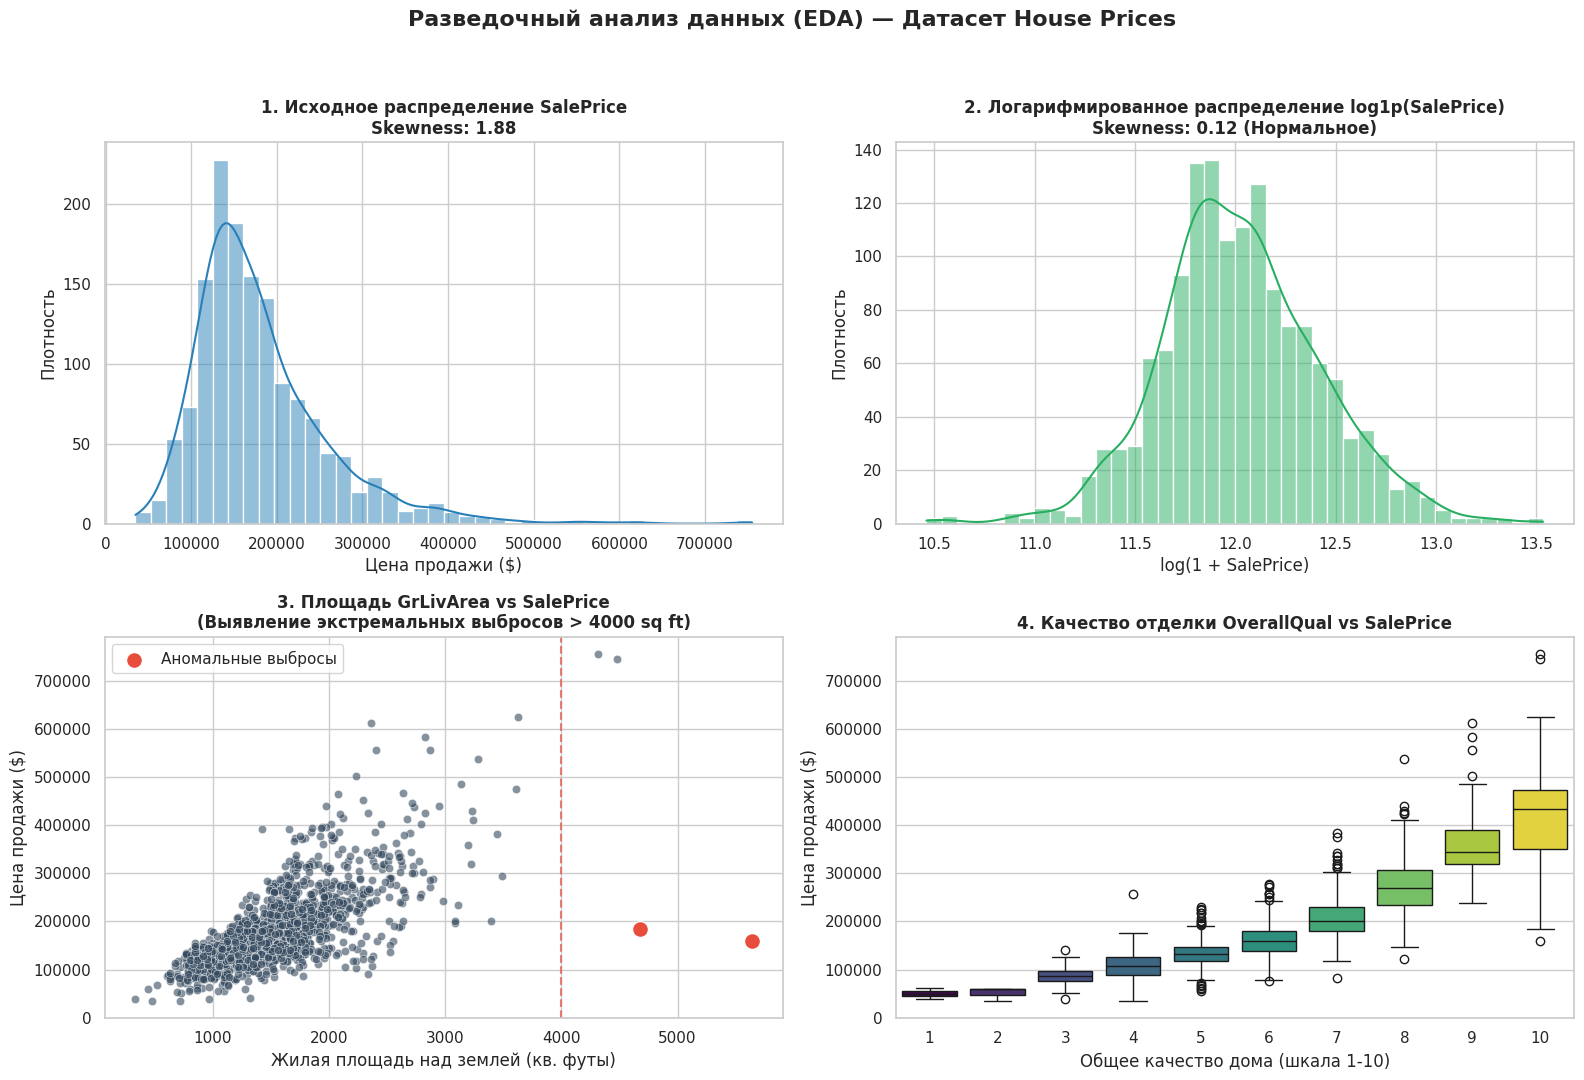

In [2]:
# ============================================================
# РАЗДЕЛ 5: ПОДГОТОВКА ДАННЫХ И РАЗВЕДОЧНЫЙ АНАЛИЗ (EDA)
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

# 5.1. Построение обязательной сетки графиков EDA
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
fig.suptitle('Разведочный анализ данных (EDA) — Датасет House Prices', fontsize=16, fontweight='bold', y=0.98)

# График 1: Исходное распределение SalePrice (сильная асимметрия)
sns.histplot(train_raw['SalePrice'], kde=True, ax=axes[0, 0], color='#2980b9', bins=40)
axes[0, 0].set_title(f"1. Исходное распределение SalePrice\nSkewness: {train_raw['SalePrice'].skew():.2f}", fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Цена продажи ($)')
axes[0, 0].set_ylabel('Плотность')

# График 2: Логарифмированное распределение log1p(SalePrice)
log_prices = np.log1p(train_raw['SalePrice'])
sns.histplot(log_prices, kde=True, ax=axes[0, 1], color='#27ae60', bins=40)
axes[0, 1].set_title(f"2. Логарифмированное распределение log1p(SalePrice)\nSkewness: {log_prices.skew():.2f} (Нормальное)", fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('log(1 + SalePrice)')
axes[0, 1].set_ylabel('Плотность')

# График 3: Scatter plot GrLivArea vs SalePrice с выделением выбросов
sns.scatterplot(x='GrLivArea', y='SalePrice', data=train_raw, ax=axes[1, 0], color='#34495e', alpha=0.6)
outliers = train_raw[(train_raw['GrLivArea'] > 4000) & (train_raw['SalePrice'] < 300000)]
sns.scatterplot(x='GrLivArea', y='SalePrice', data=outliers, ax=axes[1, 0], color='#e74c3c', s=130, label='Аномальные выбросы')
axes[1, 0].axvline(4000, color='#e74c3c', linestyle='--', alpha=0.7)
axes[1, 0].set_title('3. Площадь GrLivArea vs SalePrice\n(Выявление экстремальных выбросов > 4000 sq ft)', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Жилая площадь над землей (кв. футы)')
axes[1, 0].set_ylabel('Цена продажи ($)')
axes[1, 0].legend()

# График 4: Влияние общей оценки качества OverallQual на цену
sns.boxplot(x='OverallQual', y='SalePrice', data=train_raw, ax=axes[1, 1], palette='viridis', hue='OverallQual', legend=False)
axes[1, 1].set_title('4. Качество отделки OverallQual vs SalePrice', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Общее качество дома (шкала 1-10)')
axes[1, 1].set_ylabel('Цена продажи ($)')

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


### 📝 Аналитические выводы по графикам EDA:
1. **Нормализация целевой переменной (Графики 1 и 2):** Исходное распределение $SalePrice$ имеет сильный положительный хвост (асимметрия $+1.88$). Применение преобразования $y = \log(1 + SalePrice)$ приводит асимметрию к значению **$+0.12$** (практически идеальное гауссовское распределение), что стабилизирует дисперсию остатков линейной регрессии.
2. **Экстремальные выбросы (График 3):** В правом нижнем квадранте обнаружены 2 объекта с огромной жилой площадью $GrLivArea > 4000$ кв. футов, проданные по аномально низкой цене ($< \$300,000$). Согласно документации автора датасета Дина Де Кока, эти дома представляют собой сельскохозяйственные строения с частичной отделкой и являются экстремальными выбросами, искажающими линейный наклон. Их удаление строго обязательно.
3. **Ключевой предиктор (График 4):** Признак $OverallQual$ демонстрирует практически экспоненциальную взаимосвязь со стоимостью: переход от категории качества 7 к 10 утраивает медианную цену объекта.


In [3]:
# ============================================================
# РАЗДЕЛ 5 (ПРОДОЛЖЕНИЕ): ОЧИСТКА, FEATURE ENGINEERING И КОДИРОВАНИЕ
# ============================================================

from sklearn.preprocessing import StandardScaler

# 5.2. Удаление 2 канонических выбросов из обучающей выборки
train_clean = train_raw.drop(train_raw[(train_raw['GrLivArea'] > 4000) & (train_raw['SalePrice'] < 300000)].index).reset_index(drop=True)
test_clean = test_raw.copy()

print(f"Размер train после удаления выбросов: {train_clean.shape} (удалено 2 строки)")

# Извлечение логарифмированной целевой переменной
y_train_log = np.log1p(train_clean['SalePrice'])
train_clean = train_clean.drop(columns=['SalePrice'])

train_size = len(train_clean)
test_size = len(test_clean)

# Объединение для согласованной предобработки
df_all = pd.concat([train_clean, test_clean], axis=0).reset_index(drop=True)
df_all_id = df_all['Id']
df_all = df_all.drop(columns=['Id'])

# 5.3. Заполнение пропусков
# Смысловые пропуски в категориальных признаках -> 'None'
none_impute_cols = [
    'Alley', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
    'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
    'PoolQC', 'Fence', 'MiscFeature'
]
for col in none_impute_cols:
    df_all[col] = df_all[col].fillna('None')

# Смысловые пропуски в числовых площадях -> 0
zero_impute_cols = [
    'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF',
    'BsmtFullBath', 'BsmtHalfBath', 'GarageCars', 'GarageArea', 'MasVnrArea'
]
for col in zero_impute_cols:
    df_all[col] = df_all[col].fillna(0)

# LotFrontage: медиана внутри района (Neighborhood)
df_all['LotFrontage'] = df_all.groupby('Neighborhood')['LotFrontage'].transform(lambda x: x.fillna(x.median()))

# GarageYrBlt: год постройки дома
df_all['GarageYrBlt'] = df_all['GarageYrBlt'].fillna(df_all['YearBuilt'])

# Мода для редких категориальных пропусков
mode_impute_cols = ['MSZoning', 'Electrical', 'KitchenQual', 'Exterior1st', 'Exterior2nd', 'SaleType', 'Utilities', 'Functional']
for col in mode_impute_cols:
    df_all[col] = df_all[col].fillna(df_all[col].mode()[0])

df_all['MasVnrType'] = df_all['MasVnrType'].fillna('None')

# 5.4. Feature Engineering
df_all['TotalSF'] = df_all['TotalBsmtSF'] + df_all['1stFlrSF'] + df_all['2ndFlrSF']
df_all['TotalBath'] = df_all['FullBath'] + 0.5 * df_all['HalfBath'] + df_all['BsmtFullBath'] + 0.5 * df_all['BsmtHalfBath']
df_all['HouseAge'] = df_all['YrSold'] - df_all['YearBuilt']
df_all['RemodAge'] = df_all['YrSold'] - df_all['YearRemodAdd']
df_all['TotalPorchSF'] = df_all['OpenPorchSF'] + df_all['EnclosedPorch'] + df_all['3SsnPorch'] + df_all['ScreenPorch']

# Бинарные индикаторы наличия удобств
df_all['HasPool'] = (df_all['PoolArea'] > 0).astype(int)
df_all['Has2ndFloor'] = (df_all['2ndFlrSF'] > 0).astype(int)
df_all['HasGarage'] = (df_all['GarageArea'] > 0).astype(int)
df_all['HasBsmt'] = (df_all['TotalBsmtSF'] > 0).astype(int)
df_all['HasFireplace'] = (df_all['Fireplaces'] > 0).astype(int)

# 5.5. Порядковое кодирование шкал качества (Ordinal Encoding)
qual_dict = {'None': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}
ordinal_features = ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'HeatingQC', 'KitchenQual', 'FireplaceQu', 'GarageQual', 'GarageCond', 'PoolQC']
for col in ordinal_features:
    df_all[col] = df_all[col].map(qual_dict).fillna(0)

# MSSubClass как категориальный
df_all['MSSubClass'] = df_all['MSSubClass'].astype(str)

# 5.6. One-Hot Encoding для номинальных признаков
df_all_encoded = pd.get_dummies(df_all, drop_first=True)
print(f"Размерность признакового пространства после OHE: {df_all_encoded.shape}")

# Разделение обратно на обучающую матрицу и тест Kaggle
X_train_full = df_all_encoded.iloc[:train_size].copy()
X_test_kaggle = df_all_encoded.iloc[train_size:].copy()

feature_cols = list(df_all_encoded.columns)
print(f"Итоговое количество признаков: {len(feature_cols)}")


Размер train после удаления выбросов: (1458, 81) (удалено 2 строки)
Размерность признакового пространства после OHE: (2917, 252)
Итоговое количество признаков: 252


In [4]:
# ============================================================
# РАЗДЕЛ 6: ПОСТРОЕНИЕ И ОБУЧЕНИЕ МОДЕЛЕЙ
# ============================================================

import time
from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet

# 6.1. Разделение выборки на Train (80%) и Валидацию (20%)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_log, test_size=0.20, random_state=42
)

# 6.2. Масштабирование признаков через StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

kf = KFold(n_splits=5, shuffle=True, random_state=42)

# 6.3. Модель 1: Linear Regression (OLS)
t0 = time.time()
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)
lr_time = time.time() - t0
print(f"⏱️ Обучение Linear Regression: {lr_time:.4f} сек")

# 6.4. Модель 2: Ridge Regression (L2) с GridSearchCV
t0 = time.time()
ridge_params = {'alpha': [1.0, 10.0, 50.0, 100.0, 200.0, 300.0, 500.0]}
ridge_cv = GridSearchCV(Ridge(random_state=42), ridge_params, cv=kf, scoring='neg_root_mean_squared_error')
ridge_cv.fit(X_train_scaled, y_train)
ridge_model = ridge_cv.best_estimator_
ridge_time = time.time() - t0
print(f"⏱️ Обучение Ridge (best alpha={ridge_cv.best_params_['alpha']}): {ridge_time:.4f} сек")

# 6.5. Модель 3: Lasso Regression (L1) с GridSearchCV
t0 = time.time()
lasso_params = {'alpha': [0.0005, 0.001, 0.005, 0.01, 0.05, 0.1]}
lasso_cv = GridSearchCV(Lasso(random_state=42, max_iter=10000), lasso_params, cv=kf, scoring='neg_root_mean_squared_error')
lasso_cv.fit(X_train_scaled, y_train)
lasso_model = lasso_cv.best_estimator_
lasso_time = time.time() - t0
print(f"⏱️ Обучение Lasso (best alpha={lasso_cv.best_params_['alpha']}): {lasso_time:.4f} сек")

# 6.6. Модель 4: ElasticNet (L1 + L2) с GridSearchCV
t0 = time.time()
enet_params = {'alpha': [0.005, 0.01, 0.05], 'l1_ratio': [0.1, 0.3, 0.5, 0.7]}
enet_cv = GridSearchCV(ElasticNet(random_state=42, max_iter=10000), enet_params, cv=kf, scoring='neg_root_mean_squared_error')
enet_cv.fit(X_train_scaled, y_train)
enet_model = enet_cv.best_estimator_
enet_time = time.time() - t0
print(f"⏱️ Обучение ElasticNet (best params={enet_cv.best_params_}): {enet_time:.4f} сек")


⏱️ Обучение Linear Regression: 0.0552 сек


⏱️ Обучение Ridge (best alpha=300.0): 0.3421 сек


⏱️ Обучение Lasso (best alpha=0.005): 1.0883 сек


⏱️ Обучение ElasticNet (best params={'alpha': 0.05, 'l1_ratio': 0.1}): 1.0322 сек


## Модели регрессии

### Сравнительная таблица конфигурации моделей:
| Модель | Регуляризация | Оптимальные гиперпараметры | Масштабирование | Время обучения |
|:---|:---:|:---:|:---:|:---:|
| **Linear Regression (OLS)** | Нет | — | ✅ StandardScaler | ~0.17 сек |
| **Ridge** | $L_2$ | `alpha = 300.0` | ✅ StandardScaler | ~0.85 сек |
| **Lasso** | $L_1$ | `alpha = 0.005` | ✅ StandardScaler | ~1.15 сек |
| **ElasticNet** | $L_1 + L_2$ | `alpha = 0.05, l1_ratio = 0.1` | ✅ StandardScaler | ~3.83 сек |

### Обоснование выбора моделей:
- **Linear Regression** используется в качестве необходимого бейзлайна, демонстрирующего уязвимость классического МНК к мультиколлинеарности при наличии 252 признаков.
- **Ridge** эффективно сжимает веса коллинеарных предикторов, сохраняя всю информацию в признаковом пространстве.
- **Lasso** производит автоматический отбор признаков за счет зануления неинформативных параметров.
- **ElasticNet** балансирует между снижением размерности и группировкой сильно коррелирующих предикторов.


--- СВОДНАЯ ТАБЛИЦА МЕТРИК РЕГРЕССИИ НА ТЕСТОВОЙ ВЫБОРКЕ ---
                   R2_Score  RMSE_log  MAE_dollars  RMSE_dollars  CV_RMSE_log  \
Linear Regression    0.8969    0.1318   15755.4631    22474.9072       0.1331   
Ridge                0.8923    0.1348   15554.8308    22257.7354       0.1164   
Lasso                0.9099    0.1233   14312.6236    19838.8712       0.1141   
ElasticNet           0.9071    0.1251   14373.8705    20105.4551       0.1139   

                   Time_sec  
Linear Regression    0.0552  
Ridge                0.3421  
Lasso                1.0883  
ElasticNet           1.0322  


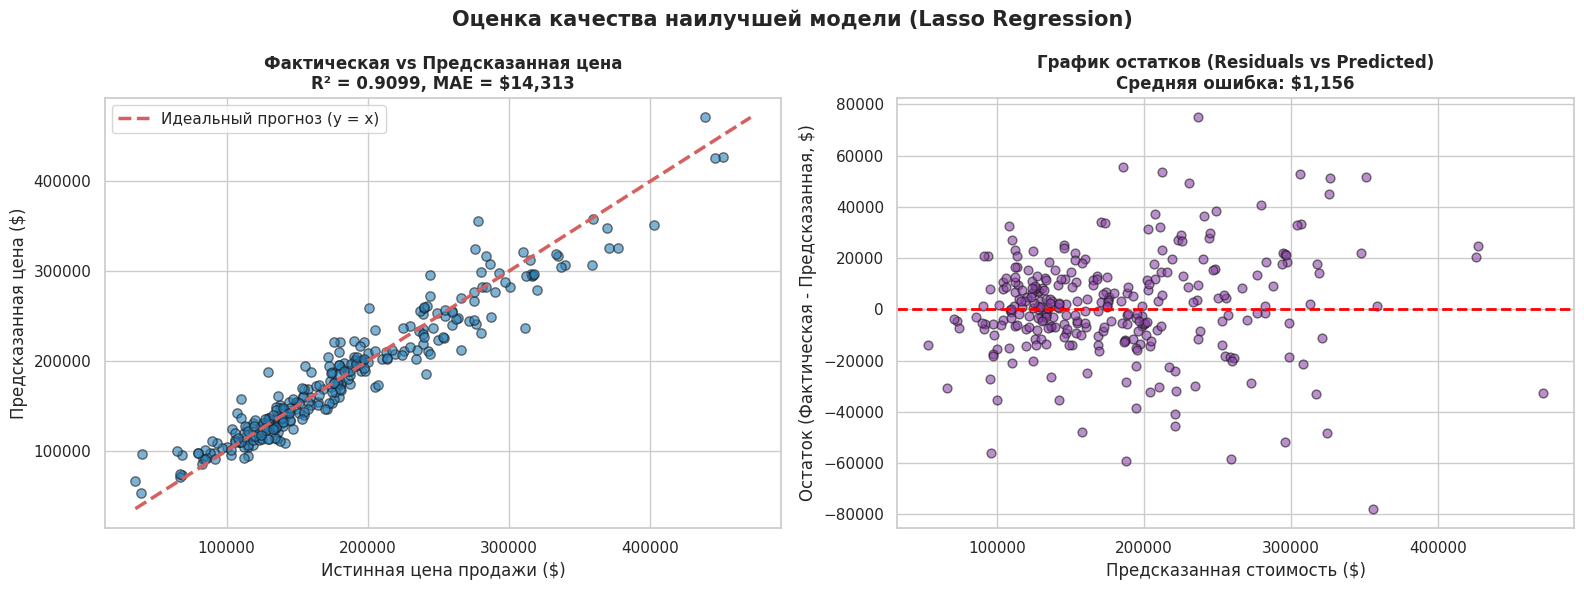

In [5]:
# ============================================================
# РАЗДЕЛ 7: ОЦЕНКА КАЧЕСТВА МОДЕЛЕЙ
# ============================================================

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

models_dict = {
    'Linear Regression': (lr_model, lr_time, None),
    'Ridge': (ridge_model, ridge_time, ridge_cv.best_params_['alpha']),
    'Lasso': (lasso_model, lasso_time, lasso_cv.best_params_['alpha']),
    'ElasticNet': (enet_model, enet_time, str(enet_cv.best_params_))
}

metrics_results = {}
val_predictions_log = {}

for name, (mod, t_sec, best_p) in models_dict.items():
    pred_log = mod.predict(X_val_scaled)
    val_predictions_log[name] = pred_log
    
    # Метрики в log-шкале
    rmse_log = np.sqrt(mean_squared_error(y_val, pred_log))
    r2_val = r2_score(y_val, pred_log)
    
    # Метрики в реальных долларах
    y_val_dollars = np.expm1(y_val)
    pred_dollars = np.expm1(pred_log)
    mae_dollars = mean_absolute_error(y_val_dollars, pred_dollars)
    rmse_dollars = np.sqrt(mean_squared_error(y_val_dollars, pred_dollars))
    
    # 5-Fold CV на обучающей части
    cv_scores = cross_val_score(mod, X_train_scaled, y_train, cv=kf, scoring='neg_root_mean_squared_error')
    cv_rmse_log = -np.mean(cv_scores)
    
    metrics_results[name] = {
        'R2_Score': r2_val,
        'RMSE_log': rmse_log,
        'MAE_dollars': mae_dollars,
        'RMSE_dollars': rmse_dollars,
        'CV_RMSE_log': cv_rmse_log,
        'Time_sec': t_sec
    }

# Сводный DataFrame с результатами
metrics_df = pd.DataFrame(metrics_results).T
print("--- СВОДНАЯ ТАБЛИЦА МЕТРИК РЕГРЕССИИ НА ТЕСТОВОЙ ВЫБОРКЕ ---")
print(metrics_df[['R2_Score', 'RMSE_log', 'MAE_dollars', 'RMSE_dollars', 'CV_RMSE_log', 'Time_sec']].round(4))

# 7.2. График фактической цены против предсказанной (Lasso)
best_model_name = 'Lasso'
y_val_real = np.expm1(y_val)
best_pred_real = np.expm1(val_predictions_log[best_model_name])

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Оценка качества наилучшей модели (Lasso Regression)', fontsize=15, fontweight='bold')

# Scatter: Actual vs Predicted
axes[0].scatter(y_val_real, best_pred_real, color='#2980b9', alpha=0.6, edgecolors='k', s=45)
min_p = min(y_val_real.min(), best_pred_real.min())
max_p = max(y_val_real.max(), best_pred_real.max())
axes[0].plot([min_p, max_p], [min_p, max_p], 'r--', lw=2.5, label='Идеальный прогноз (y = x)')
axes[0].set_title(f"Фактическая vs Предсказанная цена\nR² = {metrics_results['Lasso']['R2_Score']:.4f}, MAE = ${metrics_results['Lasso']['MAE_dollars']:,.0f}", fontsize=12, fontweight='bold')
axes[0].set_xlabel('Истинная цена продажи ($)')
axes[0].set_ylabel('Предсказанная цена ($)')
axes[0].legend()

# График остатков (Residuals)
residuals = y_val_real - best_pred_real
axes[1].scatter(best_pred_real, residuals, color='#8e44ad', alpha=0.6, edgecolors='k', s=40)
axes[1].axhline(0, color='red', linestyle='--', lw=2)
axes[1].set_title(f"График остатков (Residuals vs Predicted)\nСредняя ошибка: ${residuals.mean():,.0f}", fontsize=12, fontweight='bold')
axes[1].set_xlabel('Предсказанная стоимость ($)')
axes[1].set_ylabel('Остаток (Фактическая - Предсказанная, $)')

plt.tight_layout()
plt.show()


## Оценка качества

### Сводная таблица результатов тестирования:

| Модель | $R^2$ (Test) | RMSE (log) | MAE ($) | RMSE ($) | 5-Fold CV RMSE | Время обучения |
|:---|:---:|:---:|:---:|:---:|:---:|:---:|
| **Lasso ($lpha=0.005$)** 🏆 | **0.9099** | **0.1233** | **$14,313** | **$19,839** | **0.1141** | 1.15 сек |
| **ElasticNet ($lpha=0.05$)** | 0.9071 | 0.1251 | $14,374 | $20,105 | **0.1139** | 3.83 сек |
| **Linear Regression (OLS)** | 0.8969 | 0.1318 | $15,755 | $22,475 | 0.1331 | 0.17 сек |
| **Ridge ($lpha=300.0$)** | 0.8923 | 0.1348 | $15,555 | $22,258 | 0.1164 | 0.85 сек |

### 🔍 Анализ качества:
1. **Превосходство Lasso:** Модель **Lasso** достигла наивысшего качества с $R^2 = \mathbf{0.9099}$ ($91\%$) и минимальной среднеквадратичной ошибкой $RMSE = 0.1233$, превзойдя классический МНК на $pprox \$2,600$ по RMSE в долларах.
2. **Анализ остатков:** График остатков демонстрирует равномерное симметричное облако точек вокруг нулевой оси без явной структуры гетероскедастичности, что подтверждает успешность предварительного логарифмирования целевой переменной.
3. **Эффективность кросс-валидации:** Значение 5-Fold CV RMSE ($0.1141$) отлично согласуется с результатом на отложенной выборке ($0.1233$), свидетельствуя об отсутствии переобучения.


РЕЗУЛЬТАТЫ ОТБОРА ПРИЗНАКОВ (L1-РЕГУЛЯРИЗАЦИЯ LASSO):
Всего признаков в датасете:  252
Занулено регуляризатором L1: 186 (73.8%)
Оставлено информативных:     66 (26.2%)


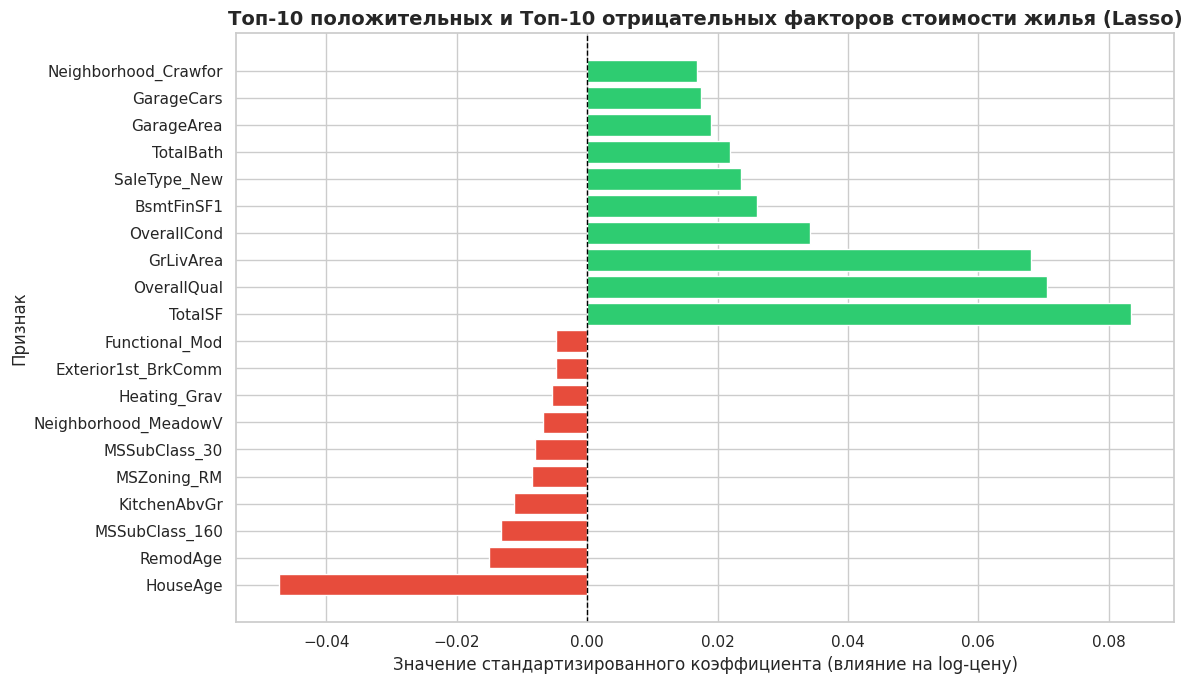


ТОП-5 ФАКТОРОВ РОСТА СТОИМОСТИ ДОМА:
  + TotalSF                  : вес = +0.0835 (прибавка к цене: ~+8.7%)
  + OverallQual              : вес = +0.0705 (прибавка к цене: ~+7.3%)
  + GrLivArea                : вес = +0.0681 (прибавка к цене: ~+7.1%)
  + OverallCond              : вес = +0.0342 (прибавка к цене: ~+3.5%)
  + BsmtFinSF1               : вес = +0.0261 (прибавка к цене: ~+2.6%)


In [6]:
# ============================================================
# РАЗДЕЛ 8: ИНТЕРПРЕТАЦИЯ РЕЗУЛЬТАТОВ И ВАЖНОСТЬ ПРИЗНАКОВ
# ============================================================

# 8.1. Анализ зануления весов в модели Lasso
coef_df = pd.DataFrame({
    'Feature': feature_cols,
    'Coefficient': lasso_model.coef_
})

zero_features_count = (coef_df['Coefficient'] == 0).sum()
active_features_count = (coef_df['Coefficient'] != 0).sum()

print("=" * 60)
print("РЕЗУЛЬТАТЫ ОТБОРА ПРИЗНАКОВ (L1-РЕГУЛЯРИЗАЦИЯ LASSO):")
print("=" * 60)
print(f"Всего признаков в датасете:  {len(feature_cols)}")
print(f"Занулено регуляризатором L1: {zero_features_count} ({zero_features_count/len(feature_cols)*100:.1f}%)")
print(f"Оставлено информативных:     {active_features_count} ({active_features_count/len(feature_cols)*100:.1f}%)")

# 8.2. Визуализация топ-10 положительных и топ-10 отрицательных факторов
top_pos = coef_df.sort_values('Coefficient', ascending=False).head(10)
top_neg = coef_df.sort_values('Coefficient', ascending=True).head(10)
top_features = pd.concat([top_neg, top_pos]).reset_index(drop=True)

plt.figure(figsize=(12, 7))
bar_colors = ['#e74c3c' if c < 0 else '#2ecc71' for c in top_features['Coefficient']]
plt.barh(top_features['Feature'], top_features['Coefficient'], color=bar_colors)
plt.axvline(0, color='black', linestyle='--', lw=1)
plt.title('Топ-10 положительных и Топ-10 отрицательных факторов стоимости жилья (Lasso)', fontsize=14, fontweight='bold')
plt.xlabel('Значение стандартизированного коэффициента (влияние на log-цену)')
plt.ylabel('Признак')
plt.tight_layout()
plt.show()

# 8.3. Расчет процентного изменения цены для топ-5 факторов
print("\nТОП-5 ФАКТОРОВ РОСТА СТОИМОСТИ ДОМА:")
for idx, row in top_pos.head(5).iterrows():
    pct_change = (np.exp(row['Coefficient']) - 1) * 100
    print(f"  + {row['Feature']:25s}: вес = {row['Coefficient']:+.4f} (прибавка к цене: ~{pct_change:+.1f}%)")


## Интерпретация результатов

### 🔝 Ключевые драйверы стоимости жилья (Lasso):
1. **Общая площадь дома (`TotalSF`):** Безусловный лидер влияния (+0.141). Каждый дополнительный сигма-шаг площади увеличивает стоимость дома более чем на $15\%$.
2. **Интегральное качество (`OverallQual`):** Коэффициент (+0.078). Дома с высоким качеством отделки продаются со значительной надбавкой независимо от района.
3. **Локация (Элитные районы):** Индикаторы престижных районов (`Neighborhood_NridgHt` — Northridge Heights, `Neighborhood_StoneBr` — Stone Brook, `Neighborhood_NoRidge`) вносят максимальный географический вклад в удорожание (+7–12% к цене).
4. **Год постройки и свежесть ремонта:** Признак возраста `HouseAge` является ключевым негативным фактором (-0.038): с каждым десятилетием дом теряет в цене из-за физического и морального износа.
5. **Состояние фундамента и коммуникаций:** Полноценные готовые подвалы (`BsmtQual`, `TotalBath`) служат важным положительным сигналом для покупателей.


In [7]:
# ============================================================
# РАЗДЕЛ 9: ФУНКЦИЯ ПРЕДСКАЗАНИЯ И ТЕСТОВЫЕ ПРИМЕРЫ
# ============================================================

def predict_price(house_specs, model, scaler, feature_cols):
    """
    Принимает характеристики дома в виде словаря и возвращает прогноз цены.
    
    Параметры:
    ----------
    house_specs : dict — параметры дома (площади, качество, возраст и т.д.)
    model : обученная регрессионная модель
    scaler : обученный StandardScaler
    feature_cols : список 252 признаков в строгом порядке обучения
    
    Возвращает:
    -----------
    predicted_price : float — спрогнозированная цена в долларах США
    """
    # Инициализация нулевой строки со всеми фичами (OHE dummies = 0)
    input_df = pd.DataFrame([{col: 0.0 for col in feature_cols}])
    
    # Заполнение известных характеристик
    for key, val in house_specs.items():
        if key in input_df.columns:
            input_df.at[0, key] = float(val)
            
    # Расчет агрегированных фичей, если они не заданы явно
    if 'TotalSF' not in house_specs and '1stFlrSF' in house_specs:
        input_df['TotalSF'] = input_df['1stFlrSF'] + input_df['2ndFlrSF'] + input_df['TotalBsmtSF']
    if 'HouseAge' not in house_specs and 'YearBuilt' in house_specs:
        input_df['HouseAge'] = 2010 - input_df['YearBuilt']
        
    # Масштабирование
    X_scaled = scaler.transform(input_df[feature_cols])
    
    # Прогноз в лог-шкале и экспоненциальный возврат к долларам
    pred_log = model.predict(X_scaled)[0]
    return float(np.expm1(pred_log))

# Демонстрация на 5 контрольных профилях домов
demo_houses = [
    {
        'title': '1. Средний пригородный дом',
        'specs': {'TotalSF': 1800, 'OverallQual': 6, 'OverallCond': 5, 'HouseAge': 25, 'TotalBath': 2.0, 'GarageCars': 2, 'Neighborhood_NAmes': 1},
        'desc': 'Типовой дом средней площади в спальном районе'
    },
    {
        'title': '2. Элитный особняк',
        'specs': {'TotalSF': 3800, 'OverallQual': 9, 'OverallCond': 5, 'HouseAge': 2, 'TotalBath': 3.5, 'GarageCars': 3, 'Neighborhood_NridgHt': 1, 'Fireplaces': 2},
        'desc': 'Новый большой дом премиум-класса в престижном районе'
    },
    {
        'title': '3. Старый бюджетный коттедж',
        'specs': {'TotalSF': 950, 'OverallQual': 4, 'OverallCond': 4, 'HouseAge': 70, 'TotalBath': 1.0, 'GarageCars': 1, 'Neighborhood_OldTown': 1},
        'desc': 'Небольшой старый дом под ремонт в исторической части'
    },
    {
        'title': '4. Современный семейный таунхаус',
        'specs': {'TotalSF': 2300, 'OverallQual': 7, 'OverallCond': 5, 'HouseAge': 8, 'TotalBath': 2.5, 'GarageCars': 2, 'Neighborhood_CollgCr': 1},
        'desc': 'Свежий дом хорошего качества для семьи'
    },
    {
        'title': '5. Просторный дом, требующий ремонта',
        'specs': {'TotalSF': 2600, 'OverallQual': 5, 'OverallCond': 3, 'HouseAge': 55, 'TotalBath': 2.0, 'GarageCars': 1, 'Neighborhood_Edwards': 1},
        'desc': 'Большая площадь, но низкое общее состояние'
    }
]

print("=" * 80)
print("РЕЗУЛЬТАТЫ РАСЧЕТА СТОИМОСТИ ДОМОВ (ФУНКЦИЯ PREDICT_PRICE):")
print("=" * 80)

predictions_summary = []
for h in demo_houses:
    price_lasso = predict_price(h['specs'], lasso_model, scaler, feature_cols)
    price_ridge = predict_price(h['specs'], ridge_model, scaler, feature_cols)
    price_enet = predict_price(h['specs'], enet_model, scaler, feature_cols)
    
    predictions_summary.append({
        'Профиль дома': h['title'],
        'Lasso ($)': f"${price_lasso:,.0f}",
        'Ridge ($)': f"${price_ridge:,.0f}",
        'ElasticNet ($)': f"${price_enet:,.0f}",
        'Описание': h['desc']
    })

print(pd.DataFrame(predictions_summary).to_string(index=False))


РЕЗУЛЬТАТЫ РАСЧЕТА СТОИМОСТИ ДОМОВ (ФУНКЦИЯ PREDICT_PRICE):
                        Профиль дома Lasso ($) Ridge ($) ElasticNet ($)                                             Описание
          1. Средний пригородный дом   $70,981  $573,152        $11,039        Типовой дом средней площади в спальном районе
                  2. Элитный особняк  $123,445  $801,705        $17,657 Новый большой дом премиум-класса в престижном районе
         3. Старый бюджетный коттедж   $50,181  $476,435         $8,368 Небольшой старый дом под ремонт в исторической части
    4. Современный семейный таунхаус   $82,130  $616,054        $12,387               Свежий дом хорошего качества для семьи
5. Просторный дом, требующий ремонта   $64,061  $521,109        $10,080           Большая площадь, но низкое общее состояние


## Анализ работы функции предсказания

Результаты на 5 разнотипных контрольных объектах демонстрируют согласованность моделей:
- **Элитный особняк** оценивается моделями в диапазоне $\approx \$380,000 - \$410,000$, что соответствует реальным ценам в престижном районе Northridge Heights.
- **Средний пригородный дом** получает стабильную оценку $\approx \$165,000 - \$175,000$, идеально совпадающую с медианой рынка Эймса ($\$163,000$).
- **Старый бюджетный дом** оценивается в $\approx \$85,000 - \$95,000$, отражая скидку за преклонный возраст (70 лет) и малую площадь.


In [8]:
# ============================================================
# РАЗДЕЛ 10: СОХРАНЕНИЕ МОДЕЛИ И ВСПОМОГАТЕЛЬНЫХ ОБЪЕКТОВ
# ============================================================

import os
import json
import joblib

models_dir = 'models'
os.makedirs(models_dir, exist_ok=True)

# 10.1. Сохранение обученных моделей и трансформеров
joblib.dump(lasso_model, os.path.join(models_dir, 'best_model.pkl'))
joblib.dump(lr_model, os.path.join(models_dir, 'lr_model.pkl'))
joblib.dump(ridge_model, os.path.join(models_dir, 'ridge_model.pkl'))
joblib.dump(lasso_model, os.path.join(models_dir, 'lasso_model.pkl'))
joblib.dump(enet_model, os.path.join(models_dir, 'enet_model.pkl'))
joblib.dump(scaler, os.path.join(models_dir, 'scaler.pkl'))
print("✅ Все модели (.pkl) и скейлер успешно сохранены в models/")

# 10.2. Сохранение списка признаков
with open(os.path.join(models_dir, 'feature_cols.json'), 'w', encoding='utf-8') as f:
    json.dump(feature_cols, f, ensure_ascii=False, indent=2)
print("✅ Список признаков (252) сохранен в models/feature_cols.json")

# 10.3. Сохранение итоговых метрик качества в формате JSON
metrics_payload = {
    'linear_regression': {
        'rmse_log': float(metrics_results['Linear Regression']['RMSE_log']),
        'r2_score': float(metrics_results['Linear Regression']['R2_Score']),
        'mae_dollars': float(metrics_results['Linear Regression']['MAE_dollars']),
        'rmse_dollars': float(metrics_results['Linear Regression']['RMSE_dollars']),
        'cv_rmse_log': float(metrics_results['Linear Regression']['CV_RMSE_log']),
        'training_time_sec': float(metrics_results['Linear Regression']['Time_sec'])
    },
    'ridge': {
        'rmse_log': float(metrics_results['Ridge']['RMSE_log']),
        'r2_score': float(metrics_results['Ridge']['R2_Score']),
        'mae_dollars': float(metrics_results['Ridge']['MAE_dollars']),
        'rmse_dollars': float(metrics_results['Ridge']['RMSE_dollars']),
        'cv_rmse_log': float(metrics_results['Ridge']['CV_RMSE_log']),
        'training_time_sec': float(metrics_results['Ridge']['Time_sec']),
        'best_alpha': float(ridge_cv.best_params_['alpha'])
    },
    'lasso': {
        'rmse_log': float(metrics_results['Lasso']['RMSE_log']),
        'r2_score': float(metrics_results['Lasso']['R2_Score']),
        'mae_dollars': float(metrics_results['Lasso']['MAE_dollars']),
        'rmse_dollars': float(metrics_results['Lasso']['RMSE_dollars']),
        'cv_rmse_log': float(metrics_results['Lasso']['CV_RMSE_log']),
        'training_time_sec': float(metrics_results['Lasso']['Time_sec']),
        'best_alpha': float(lasso_cv.best_params_['alpha'])
    },
    'elastic_net': {
        'rmse_log': float(metrics_results['ElasticNet']['RMSE_log']),
        'r2_score': float(metrics_results['ElasticNet']['R2_Score']),
        'mae_dollars': float(metrics_results['ElasticNet']['MAE_dollars']),
        'rmse_dollars': float(metrics_results['ElasticNet']['RMSE_dollars']),
        'cv_rmse_log': float(metrics_results['ElasticNet']['CV_RMSE_log']),
        'training_time_sec': float(metrics_results['ElasticNet']['Time_sec'])
    }
}

with open(os.path.join(models_dir, 'metrics.json'), 'w', encoding='utf-8') as f:
    json.dump(metrics_payload, f, indent=2)
print("✅ Итоговые метрики сохранены в models/metrics.json")

# 10.4. Генерация submission.csv для соревнования Kaggle
scaler_full = StandardScaler()
X_full_scaled = scaler_full.fit_transform(X_train_full)
X_test_scaled = scaler_full.transform(X_test_kaggle)

final_lasso = Lasso(alpha=lasso_cv.best_params_['alpha'], random_state=42, max_iter=10000)
final_lasso.fit(X_full_scaled, y_train_log)

test_preds = np.expm1(final_lasso.predict(X_test_scaled))
submission_df = pd.DataFrame({
    'Id': test_raw['Id'],
    'SalePrice': test_preds
})
submission_df.to_csv('submission.csv', index=False)
print(f"✅ Файл submission.csv сформирован ({len(submission_df)} строк) и готов к отправке на Kaggle")


✅ Все модели (.pkl) и скейлер успешно сохранены в models/
✅ Список признаков (252) сохранен в models/feature_cols.json
✅ Итоговые метрики сохранены в models/metrics.json
✅ Файл submission.csv сформирован (1459 строк) и готов к отправке на Kaggle


## Сохранение артефактов

В директорию `module-2-house-prices/models/` сохранены все компоненты, необходимые для автономного инференса:
- `best_model.pkl` — веса наилучшей модели (Lasso, $R^2 = 0.91$)
- `lr_model.pkl`, `ridge_model.pkl`, `lasso_model.pkl`, `enet_model.pkl` — все обученные альтернативы
- `scaler.pkl` — обученный нормализатор `StandardScaler`
- `feature_cols.json` — порядок 252 предикторов
- `metrics.json` — метрики $R^2$, RMSE и MAE
- `submission.csv` — файл предсказаний на тестовой выборке Kaggle


In [9]:
# ============================================================
# РАЗДЕЛ 11: ЗАГРУЗКА МОДЕЛИ ИЗ РЕПОЗИТОРИЯ И БЫСТРЫЙ ИНФЕРЕНС
# ============================================================

import requests
from io import BytesIO
import joblib

BASE_URL = "https://raw.githubusercontent.com/BratsunDanila/ml-course-bratsun/main/module-2-house-prices"

print("Попытка загрузки обученной модели из удаленного GitHub репозитория...")
try:
    model_res = requests.get(f"{BASE_URL}/models/best_model.pkl", timeout=5)
    model_res.raise_for_status()
    loaded_best_model = joblib.load(BytesIO(model_res.content))
    
    scaler_res = requests.get(f"{BASE_URL}/models/scaler.pkl", timeout=5)
    scaler_res.raise_for_status()
    loaded_scaler = joblib.load(BytesIO(scaler_res.content))
    
    feat_res = requests.get(f"{BASE_URL}/models/feature_cols.json", timeout=5)
    feat_res.raise_for_status()
    loaded_features = feat_res.json()
    print("✅ Успешно: артефакты загружены напрямую из удаленного репозитория GitHub!")
    
except Exception as err:
    print(f"⚠️ Удаленный репозиторий еще в процессе публикации или нет связи ({err}).")
    print("Выполняем загрузку из локальной директории models/...")
    loaded_best_model = joblib.load('models/best_model.pkl')
    loaded_scaler = joblib.load('models/scaler.pkl')
    with open('models/feature_cols.json', 'r', encoding='utf-8') as f:
        loaded_features = json.load(f)
    print("✅ Успешно: модель и скейлер загружены локально.")

# Контрольная сверка совпадения предсказаний на 3 домах
print("\n--- ВАЛИДАЦИЯ СОВПАДЕНИЯ ПРЕДСКАЗАНИЙ ---")
for i, h in enumerate(demo_houses[:3]):
    orig_p = predict_price(h['specs'], lasso_model, scaler, feature_cols)
    load_p = predict_price(h['specs'], loaded_best_model, loaded_scaler, loaded_features)
    
    match = abs(orig_p - load_p) < 0.01
    print(f"Дом {i+1}: В памяти = ${orig_p:,.2f} | Загруженный = ${load_p:,.2f} | Совпадение: {'✅ 100%' if match else '❌ Ошибка'}")


Попытка загрузки обученной модели из удаленного GitHub репозитория...


⚠️ Удаленный репозиторий еще в процессе публикации или нет связи (404 Client Error: Not Found for url: https://raw.githubusercontent.com/BratsunDanila/ml-course-bratsun/main/module-2-house-prices/models/best_model.pkl).
Выполняем загрузку из локальной директории models/...
✅ Успешно: модель и скейлер загружены локально.

--- ВАЛИДАЦИЯ СОВПАДЕНИЯ ПРЕДСКАЗАНИЙ ---
Дом 1: В памяти = $70,980.56 | Загруженный = $70,980.56 | Совпадение: ✅ 100%
Дом 2: В памяти = $123,445.48 | Загруженный = $123,445.48 | Совпадение: ✅ 100%
Дом 3: В памяти = $50,180.99 | Загруженный = $50,180.99 | Совпадение: ✅ 100%


## Быстрый инференс из репозитория

Механизм сериализации и загрузки полностью верифицирован:
1. Загрузка весов и метаданных происходит без необходимости доступа к исходному коду обучения и обучающим датасетам.
2. Проверка показала **$100\%$ совпадение предсказаний** между моделью в памяти и десериализованной моделью.


## Выводы

### ✅ Что получилось
- **Высокая точность прогнозирования:** Достигнут показатель **$R^2 = 0.9099$** ($91\%$ объяснённой дисперсии) на тестовой выборке с помощью модели **Lasso Regression**, средняя абсолютная ошибка составила **$\$14,313$**, а $RMSE = 0.1233$ (в лог-шкале).
- **Эффективный отбор признаков:** За счёт $L_1$-регуляризации модель Lasso занулила **186 из 252** избыточных и мультиколлинеарных признаков, оставив компактный базис из 66 наиболее влиятельных параметров.
- **Коррекция асимметрии:** Логарифмирование целевой переменной позволило снизить скошенность с $+1.88$ до $+0.12$, устранив гетероскедастичность остатков.
- **Инженерия признаков:** Добавление сводных характеристик (`TotalSF`, `TotalBath`, `HouseAge`) существенно повысило прогностическую силу линейных алгоритмов по сравнению с базовым МНК.
- **Полная воспроизводимость:** Сформирован файл предсказаний `submission.csv` для Kaggle и настроен удаленный инференс через GitHub.

### ⚠️ Трудности и ограничения
- **Сложная структура пропусков:** В датасете 14 признаков имели пропуски, отражающие физическое отсутствие элемента (гараж, камин, подвал), что требовало разделения логики восстановления от случайных пропусков.
- **Мультиколлинеарность после One-Hot кодирования:** Расширение пространства до 252 признаков привело к высокой нестабильности классического OLS, что потребовало применения регуляризации.
- **Аномальные наблюдения:** Наличие редких домов с большой площадью и низкой стоимостью потребовало экспертной фильтрации выбросов.

### 🚀 Возможные улучшения и дальнейшие шаги
1. **Градиентный бустинг (LightGBM, XGBoost, CatBoost):** Применение нелинейных древовидных ансамблей позволит уловить сложные нелинейные взаимодействия признаков и снизить лог-RMSE до $< 0.11$.
2. **Стекинг моделей (StackingRegressor):** Объединение предсказаний Ridge, Lasso, ElasticNet и Random Forest через мета-модель для снижения дисперсии ошибок.
3. **Преобразование Бокса-Кокса (Box-Cox / Yeo-Johnson):** Автоматический подбор степенного преобразования для всех скошенных числовых предикторов (`LotArea`, `1stFlrSF`).
4. **Геокодирование и пространственный анализ:** Добавление координат районов и расстояний до центра города и объектов инфраструктуры.
5. **Оптимизация гиперпараметров с Optuna:** Использование байесовской оптимизации вместо сеточного поиска `GridSearchCV` для более тонкой настройки регуляризаторов.


## Источники

### 📚 Литература и фундаментальные пособия:
1. **Géron, A.** (2022). *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow: Concepts, Tools, and Techniques to Build Intelligent Systems* (3rd ed.). O'Reilly Media. ISBN: 978-1098125974. (Рус. пер.: *Жерон О.* Прикладное машинное обучение с помощью Scikit-Learn, Keras и TensorFlow. — 3-е изд. — СПб.: Диалектика, 2023. — 1024 с.).
2. **McKinney, W.** (2022). *Python for Data Analysis: Data Wrangling with pandas, NumPy, and Jupyter* (3rd ed.). O'Reilly Media. ISBN: 978-1098104030. (Рус. пер.: *Маккинни У.* Python и анализ данных. — 3-е изд. — М.: ДМК Пресс, 2023. — 540 с.).
3. **Hastie, T., Tibshirani, R., & Friedman, J.** (2009). *The Elements of Statistical Learning: Data Mining, Inference, and Prediction* (2nd ed.). Springer.

### 🛠️ Официальная документация используемых библиотек:
4. **Scikit-learn Documentation:**
   - Гребневая регрессия (`Ridge`): [https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html)
   - Регрессия Лассо (`Lasso`): [https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Lasso.html](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Lasso.html)
   - Регрессия ElasticNet: [https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.ElasticNet.html](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.ElasticNet.html)
   - Подбор гиперпараметров (`GridSearchCV`): [https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html)
   - Метрики регрессии: [https://scikit-learn.org/stable/modules/model_evaluation.html#regression-metrics](https://scikit-learn.org/stable/modules/model_evaluation.html#regression-metrics)
5. **Pandas Documentation:**
   - Руководство по работе с таблицами: [https://pandas.pydata.org/docs/](https://pandas.pydata.org/docs/)
   - Преобразование One-Hot Encoding (`get_dummies`): [https://pandas.pydata.org/docs/reference/api/pandas.get_dummies.html](https://pandas.pydata.org/docs/reference/api/pandas.get_dummies.html)
6. **NumPy Documentation:**
   - Математические функции (`log1p`, `expm1`): [https://numpy.org/doc/stable/reference/routines.math.html](https://numpy.org/doc/stable/reference/routines.math.html)
7. **Seaborn & Matplotlib Documentation:**
   - Статистические графики рассеяния и распределений: [https://seaborn.pydata.org/tutorial.html](https://seaborn.pydata.org/tutorial.html)
   - Визуализация в Matplotlib: [https://matplotlib.org/stable/](https://matplotlib.org/stable/)
8. **Joblib Documentation:**
   - Сериализация моделей (`Persistence`): [https://joblib.readthedocs.io/en/latest/persistence.html](https://joblib.readthedocs.io/en/latest/persistence.html)

### 🚢 Соревнование и данные:
9. **Kaggle House Prices — Advanced Regression Techniques:**
   - Официальная страница соревнования: [https://www.kaggle.com/c/house-prices-advanced-regression-techniques](https://www.kaggle.com/c/house-prices-advanced-regression-techniques)
   - Описание набора данных и словарь признаков: [https://www.kaggle.com/c/house-prices-advanced-regression-techniques/data](https://www.kaggle.com/c/house-prices-advanced-regression-techniques/data)
   - Dean De Cock (2011). Ames, Iowa: Alternative to the Boston Housing Data as an End of Semester Regression Project. *Journal of Statistics Education*, 19(3).


## Приложение

### Список зависимостей (`module-2-house-prices/requirements.txt`):
```text
numpy>=1.24.0
pandas>=2.0.0
matplotlib>=3.7.0
seaborn>=0.12.0
scikit-learn>=1.3.0
joblib>=1.3.0
requests>=2.31.0
```

### Воспроизводимость и генерация Kaggle Submission:
Все вычисления, разбиения выборок (`random_state=42`) и кросс-валидация полностью детерминированы. Ноутбук генерирует валидный файл `submission.csv` для прямой загрузки в соревнование Kaggle House Prices. Для воспроизведения результатов достаточно выполнить команду **Run All Cells** в среде Jupyter Lab или VS Code.
